# Reaction Coordinate Data

:::{div}
:class: colab-badge
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/blinkletter/UsingPsi4/blob/main/book/09-DielsAlder/092-ScanData.ipynb)
:::

In the [previous notebook](091-DielsAlder.ipynb) we ran 32 constrained optimizations of cyclohexene, stretching the C3&ndash;C5 and C4&ndash;C6 bonds from 1.45 to 3.00 &Aring;, and saved the results in the file `cyclohexene_scan_HF631Gs.json`. If you open it in a text editor you will see 32 **records** of data, one for each bond length, each looking like this.

```text
  {
    "Distance":1.45,
    "Final distance":1.4501...,
    "Energy":-232.99...,
    "Steps":...
  },
```

The bond length that we asked for comes first, then the bond length measured after the optimization. The energy follows and the value is in units of Hartrees/molecule. We will want to convert that to *kJ/mol*. Last is the number of optimization steps.

In the *GAMESS* book, the equivalent file was a jumble of text lines pulled out of the log files with *grep*, and half of the notebook was spent cutting it into columns. JSON files keep the column **names** with the data, so our job is easier.

This notebook does not run *Psi4*, so the hidden first cell only imports *NumPy*, *pandas*, *Matplotlib* and *SciPy* and applies the plot style sheet.

In [1]:
####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline

# Plot style sheets from the book's GitHub repository
if IN_COLAB and not Path("styles/tufte.mplstyle").exists():
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4/main/styles/tufte.mplstyle
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4/main/styles/S2_classic2.mplstyle

if IN_COLAB:
    plt.style.use("styles/tufte.mplstyle")
else:
    plt.style.use("../../styles/tufte.mplstyle")

## Import Raw Data

We will do everything using the data analysis tools of *Python* and *pandas*. First we will import the data as a dataframe. If you ran the previous notebook, the data file is in the same folder as this notebook. If not (on *Google Colab*, for example), we will download my copy from the book's *GitHub* repository.

In [2]:
url = "https://raw.githubusercontent.com/blinkletter/UsingPsi4/main/book/09-DielsAlder/"

def load_scan(filename):
    if Path(filename).exists():
        return pd.read_json(filename)
    else:
        return pd.read_json(url + filename)

df = load_scan("cyclohexene_scan_HF631Gs.json")
df.head()

,Distance,Final distance,Energy,Steps
0,1.45,1.45,-232.999550,7
1,1.50,1.50,-233.007405,6
2,1.55,1.55,-233.009127,6
3,1.60,1.60,-233.006111,6
4,1.65,1.65,-232.999486,9


| Line | Notes |
| :---- | :---- |
| `url = ...` | The web address of this chapter's folder in the book's *GitHub* repository. |
| `Path(filename).exists()` | `True` if the file is in the same folder as this notebook. |
| `pd.read_json(...)` | Reads a JSON file, from the disk or from the web, and makes a **dataframe**. |
| `df.head()` | Shows the first five rows. |

Python will scream at you if you make a mistake and you will be able to fix any problems.

## Cleaning the Data

Data cleaning is half the work in data analysis. We need to drop empty records and malformed records. In our scan, a job that ran out of optimization steps was recorded with an energy of *NaN* ("not a number"). We will drop any such records. We also only need three of the columns: the bond length, the energy and the number of steps.

In [3]:
coord = df.dropna(subset=["Energy"])
coord = coord[["Distance", "Energy", "Steps"]].copy()
coord["Distance"] = coord["Distance"].round(2)

print(len(df) - len(coord), "records dropped")
coord.head()

0 records dropped


,Distance,Energy,Steps
0,1.45,-232.999550,7
1,1.50,-233.007405,6
2,1.55,-233.009127,6
3,1.60,-233.006111,6
4,1.65,-232.999486,9


| Line | Notes |
| :---- | :---- |
| `df.dropna(subset=["Energy"])` | A new dataframe **without** the rows that have *NaN* in the `Energy` column. |
| `coord[["Distance", "Energy", "Steps"]].copy()` | Keep only these three **columns**, as a new dataframe. Note the double square brackets: the inner pair is a *Python* list of column names. |
| `coord["Distance"].round(2)` | Rounds the bond lengths to two decimals. When *pandas* reads a number like 1.9 from a JSON file it can come back as 1.9000000000000001. That looks the same when printed, but it is **not equal** to 1.9, and it spoiled the comparison with *GAMESS* below until I added this line. Computers and decimal numbers do not always get along. |

No records were dropped. Every scan point converged.

## Processing the Data

We now have a cleaned up data set. We could have done all of this in a spreadsheet by importing the text file and deleting unwanted columns manually. *Python* and *pandas* may seem like a bit of work but it is not any more than you would do setting up the data in a spreadsheet, and the next time we only have to press "run".

We know that a Hartree is 2625.50 *kJ/mol*. So we can convert the energy to a more familiar unit. Then we should set our lowest energy structure as the zero reference and subtract that value from all the energies to establish a relative scale.

In [4]:
hartree_conversion = 2625.4996

lowest_energy = coord["Energy"].min()
coord["DeltaE"] = (coord["Energy"] - lowest_energy) * hartree_conversion
coord.round(4)

,Distance,Energy,Steps,DeltaE
0,1.45,-232.9995,7,25.1463
1,1.50,-233.0074,6,4.5214
2,1.55,-233.0091,6,0.0000
3,1.60,-233.0061,6,7.9180
4,1.65,-232.9995,9,25.3131
5,1.70,-232.9902,9,49.7870
6,1.75,-232.9789,9,79.3599
7,1.80,-232.9663,9,112.3847
8,1.85,-232.9530,9,147.4652
9,1.90,-232.9393,16,183.3906


| Line | Notes |
| :---- | :---- |
| `hartree_conversion = 2625.4996` | *kJ/mol* per Hartree. This is the value stored in `psi4.constants.hartree2kJmol`, but we did not import *Psi4* in this notebook. (In the *GAMESS* book I used 2625.7.) |
| `coord["Energy"].min()` | The **lowest** energy in the column. |
| `coord["DeltaE"] = ...` | A new column of **relative** energies in *kJ/mol*. |

The lowest energy is at 1.55 &Aring;, the closest point to the C&ndash;C bond length of relaxed cyclohexene (1.54 &Aring;). The highest point, at 2.20 &Aring;, is 340.05 *kJ/mol* above it.

## Plotting the Profile

Now we have a set of data that we can plot. Let us visualize the profile using the *Matplotlib* library.

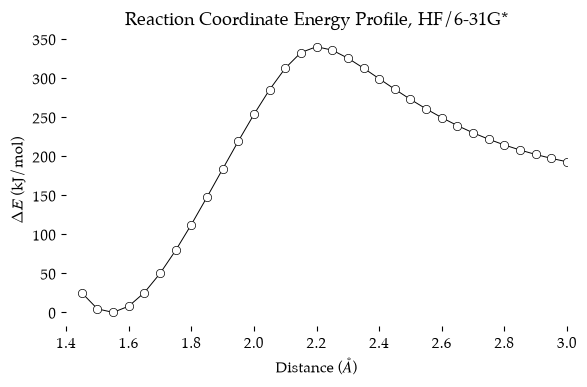

In [5]:
x = coord["Distance"]
y = coord["DeltaE"]

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(6,4))
ax.plot(x, y, color="black", linewidth=0.7, marker="o",
        markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5)
ax.set_xlabel(r"Distance ($\AA$)")
ax.set_ylabel(r"$\Delta E$ (kJ/mol)")
ax.set_title("Reaction Coordinate Energy Profile, HF/6-31G*")
ax.set_xlim(1.4, 3.0)
plt.show()

A steep climb from the cyclohexene well to a single sharp **maximum** at 2.20 &Aring;, then a slower descent as ethylene pulls away. At 3.00 &Aring; we are still 192.76 *kJ/mol* above the bottom and the curve is levelling off. The products, butadiene and ethylene at infinite distance, would be lower still.

## Publication Quality

The plot above uses the style sheet that I edited to my preference (`tufte.mplstyle`, applied in the hidden first cell). Different journals have different standards for plots. Just follow their instructions. Many will have style sheets available for your word processor or for $\LaTeX$. Use the `savefig()` method of the `fig` object to save the plot as a file. The `.pdf` extension will tell it to save in PDF format.

```python
fig.savefig("coord_profile.pdf")
```

## A Smooth Curve

The plot above is a "connect-the-dots" style plot. There are many data points and it looks fine. We do not have an exact function to which to fit the data but we could apply the infamous "cubic spline." We will use the `CubicSpline` function available from the `scipy.interpolate` library ([Documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.interpolate.CubicSpline.html)) to generate a function that represents the curve fit. We will then feed an *x*-axis of many data points into that function to create an *x*,*y* data set that represents that curve fit as a smooth line.

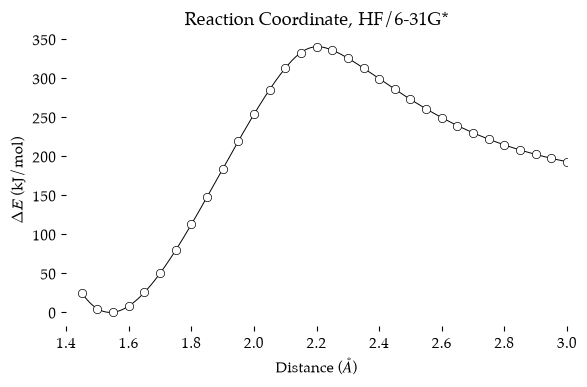

Spline maximum: 2.203 Angstrom, 340.07 kJ/mol


In [6]:
cs = CubicSpline(coord["Distance"], coord["DeltaE"])
x_fit = np.arange(1.45, 3.0001, 0.001)
y_fit = cs(x_fit)

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(6,4))
ax.plot(x_fit, y_fit, color="black", linewidth=0.7, zorder=1)
ax.plot(coord["Distance"], coord["DeltaE"], linestyle="none", marker="o",
        markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5, zorder=2)
ax.set_xlabel(r"Distance ($\AA$)")
ax.set_ylabel(r"$\Delta E$ (kJ/mol)")
ax.set_title("Reaction Coordinate, HF/6-31G*")
ax.set_xlim(1.4, 3.0)
plt.show()

i_max = np.argmax(y_fit)
print(f"Spline maximum: {x_fit[i_max]:.3f} Angstrom, {y_fit[i_max]:.2f} kJ/mol")

| Line | Notes |
| :---- | :---- |
| `CubicSpline(x, y)` | Makes a **function** `cs` that passes smoothly through every data point. |
| `np.arange(1.45, 3.0001, 0.001)` | Bond lengths from 1.45 to 3.00 &Aring;, every 0.001 &Aring;. |
| `cs(x_fit)` | The **value** of the spline at each of those bond lengths. |
| `zorder=1`, `zorder=2` | The curve is drawn **underneath** the data points. |
| `np.argmax(y_fit)` | The **position** of the largest value in the list. We use it to look up the matching bond length. |

The spline puts the maximum at 2.203 &Aring; and 340.07 *kJ/mol*. The optimized transition state in the previous notebook has C3&ndash;C5 bonds of 2.2023 &Aring; and is 340.06 *kJ/mol* above the 1.55 &Aring; scan point (340.26 above relaxed cyclohexene). The spline got the top of the barrier right to 0.001 &Aring; and 0.01 *kJ/mol*. That is unusually good, because our points are close together and the top of the curve is smooth. A spline is only a **guess** between our data points. The honest way to find the top of the barrier is a transition state optimization, which we did in the previous notebook.

## Comparing with *GAMESS*

We ran the same scan at the same level of theory in the *GAMESS* book. Here are the *GAMESS* energies for the same 32 bond lengths, typed in from the `results.txt` file of that book. Let us put both profiles on one plot. Each profile is relative to its own lowest point.

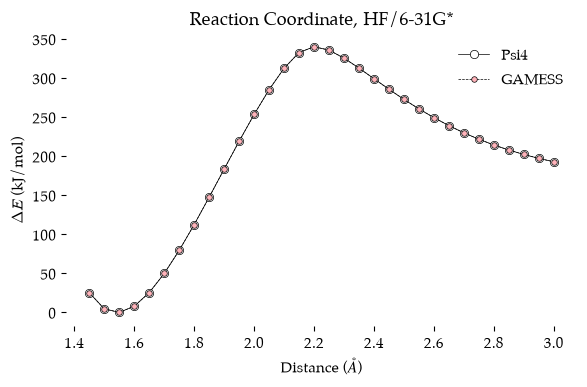

,Distance,GAMESS Energy,Energy,GAMESS DeltaE,Psi4 DeltaE,Difference
0,1.45,-232.999550,-232.999550,25.15,25.15,1.959000e-07
1,1.50,-233.007405,-233.007405,4.52,4.52,-1.159000e-07
2,1.55,-233.009127,-233.009127,0.00,0.00,-1.067000e-07
3,1.60,-233.006111,-233.006111,7.92,7.92,-5.749999e-08
4,1.65,-232.999486,-232.999486,25.31,25.31,-1.231000e-07
5,1.70,-232.990164,-232.990164,49.79,49.79,-4.120002e-08
6,1.75,-232.978901,-232.978901,79.36,79.36,-8.249998e-08
7,1.80,-232.966322,-232.966322,112.38,112.38,-1.267000e-07
8,1.85,-232.952961,-232.952961,147.47,147.47,-1.914000e-07
9,1.90,-232.939279,-232.939277,183.39,183.39,1.197300e-06


In [7]:
gamess = [-232.9995497493, -233.0074050634, -233.0091271727, -233.0061114211, -232.9994858977,
          -232.9901643852, -232.9789005901, -232.9663220865, -232.9529605653, -232.9392786848,
          -232.9256963349, -232.9126284280, -232.9005442078, -232.8900966067, -232.8824624035,
          -232.8796092131, -232.8812781492, -232.8851867409, -232.8900395999, -232.8952063985,
          -232.9003522433, -232.9052913516, -232.9099213808, -232.9141903297, -232.9180777391,
          -232.9215830460, -232.9247190604, -232.9275067283, -232.9299717690, -232.9321410104,
          -232.9340442270, -232.9357093441]

comparison = pd.DataFrame({"Distance": np.round(np.arange(1.45, 3.001, 0.05), 2),
                           "GAMESS Energy": gamess})
comparison = comparison.merge(coord[["Distance", "Energy"]], on="Distance", how="left")
comparison["GAMESS DeltaE"] = (comparison["GAMESS Energy"] - comparison["GAMESS Energy"].min()) * hartree_conversion
comparison["Psi4 DeltaE"] = (comparison["Energy"] - comparison["Energy"].min()) * hartree_conversion
comparison["Difference"] = comparison["Energy"] - comparison["GAMESS Energy"]

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(6,4))
ax.plot(comparison["Distance"], comparison["Psi4 DeltaE"], color="black", linewidth=0.5,
        marker="o", markerfacecolor="white", markeredgecolor="black", markeredgewidth=0.5,
        label="Psi4", zorder=2)
ax.plot(comparison["Distance"], comparison["GAMESS DeltaE"], color="black", linewidth=0.5,
        linestyle="--", marker="o", markersize=4, markerfacecolor="#FFB3BA",
        markeredgecolor="black", markeredgewidth=0.5, label="GAMESS", zorder=3)
ax.set_xlabel(r"Distance ($\AA$)")
ax.set_ylabel(r"$\Delta E$ (kJ/mol)")
ax.set_title("Reaction Coordinate, HF/6-31G*")
ax.legend()
plt.show()

comparison.round({"Energy": 8, "GAMESS DeltaE": 2, "Psi4 DeltaE": 2})

| Line | Notes |
| :---- | :---- |
| `gamess = [...]` | The final energies of the 32 *GAMESS* scan points (Hartree), in order from 1.45 to 3.00 &Aring;. |
| `pd.DataFrame({...})` | A table with the bond lengths and the *GAMESS* energies. |
| `.merge(coord[...], on="Distance", how="left")` | Adds the *Psi4* energy to each row with the **same** bond length. `how="left"` keeps every *GAMESS* row, even if the *Psi4* point is missing. |
| `comparison["Difference"]` | *Psi4* minus *GAMESS*, in Hartree. |
| `linestyle="--"`, `markersize=4` | The *GAMESS* points are smaller, pink and joined by a dashed line, so we can see the *Psi4* points behind them. |

The two plots lie exactly on top of each other. The `Difference` column shows why: the *Psi4* and *GAMESS* energies agree to better than 2 &times; 10<sup>&minus;6</sup> Hartree (0.005 *kJ/mol*) at every point, and to about 10<sup>&minus;7</sup> Hartree at most of them. The largest differences are between 1.90 and 2.05 &Aring;, where *Psi4* is about 1.2&ndash;1.6 &times; 10<sup>&minus;6</sup> Hartree higher, because of its slightly looser convergence criteria. *GAMESS* started every point from cyclohexene and *Psi4* started each point from the previous one, but they found the same structures. Two different programs, two different optimizers, two different ways of holding the bonds, and the same answer. That is reassuring.

## Saving the Data

We have imported, cleaned and processed the data. Maybe we should save our work so we can use this data set directly and easily next time. The dataframe object contains methods to do this. We will use the `pandas.DataFrame.to_csv()` method ([documentation](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_csv.html)) to save the dataframe object as a CSV text file.

In [8]:
comparison.to_csv("coord_profile.csv", index=False)

| Line | Notes |
| :---- | :---- |
| `index=False` | Do not write the row numbers (0, 1, 2&hellip;) into the file. |

The reaction coordinate energy profile data is now saved in a file named `coord_profile.csv`, with one row for each bond length and columns for both programs.

```{warning} AI Statement
:class: dropdown
This page is an adaptation of the "Data Workflow" notebook for the Diels-Alder chapter of my [previous web book on using *GAMESS*](https://blinkletter.github.io/UsingGAMESS). About **a third** of the text is **my own work**, carried over word for word or lightly edited, including the descriptions of importing, cleaning, processing, plotting and saving the data and the cubic spline. The **rest of the page** was written by an **LLM system** at my request. I asked it to read the JSON file written by the *Psi4* calculation notebook instead of the *GAMESS* log file extracts, to find the maximum from the spline and to compare the *Psi4* and *GAMESS* profiles. The *Python* code, the line-by-line explanations of it and the commentary on the results were written by the LLM. The numbers quoted in the text come from my own calculations.
```